# Task 1
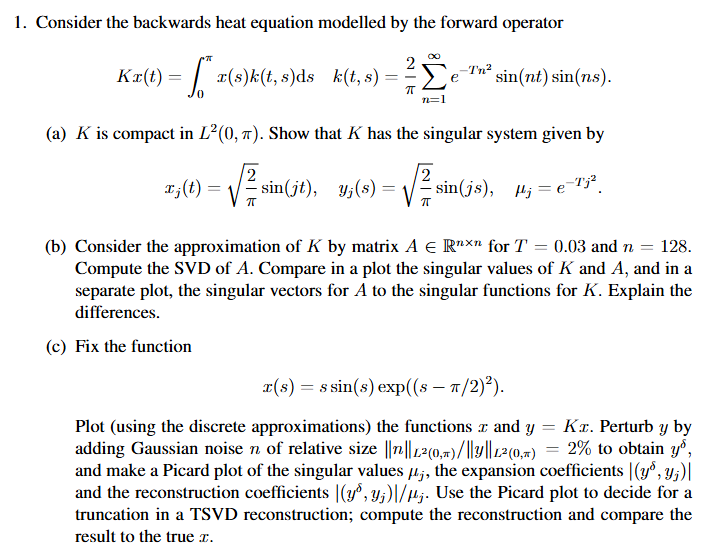

In [21]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.core.magic import register_cell_magic
from scipy.linalg import toeplitz

OUTPUT_DIR = Path("./output")
OUTPUT_DIR.mkdir(exist_ok=True)

mm = 1 / 25.4  # mm in inches
## #context layout(size => size.width.mm())
PAPER_WIDTH_IN = 259.3 * mm
TITLE_SIZE_PT = 18

sns.set_theme(context="talk", style="whitegrid")


# Magic command to export to file
@register_cell_magic
def write_and_run(line, cell):
    argz = line.split()
    file = argz[-1]
    mode = "w"
    if len(argz) == 2 and argz[0] == "-a":
        mode = "a"
    with open(file, mode, encoding="UTF-8") as f:
        f.write(cell)
    get_ipython().run_cell(cell)

In [22]:
# Based on: https://stackoverflow.com/a/29261252/5036246
def sci_notation(number, sig_fig=2, latex_style=True, omit_coeff_if_unity=True):
    ret_string = "{0:.{1:d}e}".format(number, sig_fig)
    a, b = ret_string.split("e")

    # Calculate factor part
    factor = ""
    joiner = ""
    if omit_coeff_if_unity and float(a) == 1.0:
        factor = ""
        joiner = ""
    else:
        factor = a
        joiner = "×"

    # Calculate exponent part
    b = int(b)
    exponent = ""
    if latex_style:
        exponent = f"10^{{{str(b)}}}"
    else:
        exponent = f"10^{str(b)}"

    return factor + joiner + exponent

## 1.b
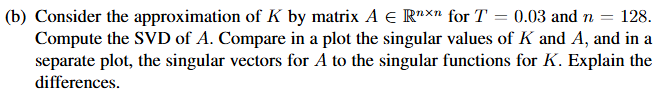

C:\Users\jeppe\AppData\Local\Temp\ipykernel_21928\2601613834.py:65: UserWarning: Tight layout not applied. tight_layout cannot make Axes height small enough to accommodate all Axes decorations.
  fig.tight_layout()


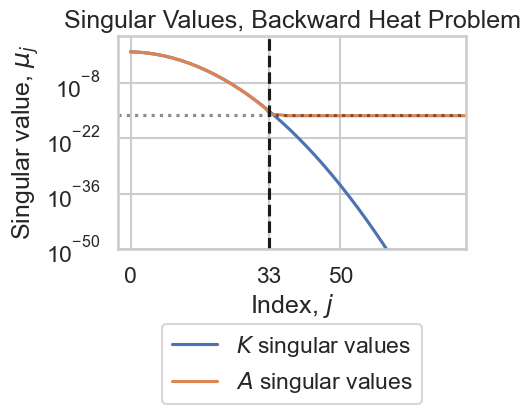

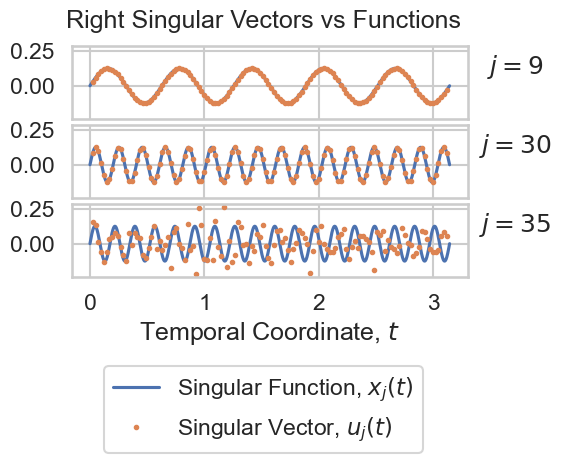

In [23]:
T = 0.03
n = 128

k = np.arange(1, n + 1)
t = k * np.pi / (n + 1)
s = k * np.pi / (n + 1)

# We construct A matrix using spectral method
# Alternative would be to use a quadrature rule

# Create left and right singular vectors sampled at t_i, s_i
j = np.arange(1, n + 1)
U = np.sqrt(2 / (n + 1)) * np.sin(np.einsum("i,j->ij", t, k))
V = np.sqrt(2 / (n + 1)) * np.sin(np.einsum("i,j->ij", s, k))
assert np.allclose(U.T @ U, np.eye(n)), "V is not orthogonal"
assert np.allclose(V.T @ V, np.eye(n)), "V is not orthogonal"

# Create diagonal matrix S of singular values
S = np.diag(np.exp(-(j**2) * T))

# Now we can construct A = U D V^*
A = U @ S @ V.T

# Now we can compare as requested in assignment
# This is almost cheating since we constructed A from its SVD
# But it would yield the same results if constructed using a sufficiently
# accurate quadrature rule
U_svd, S_svd, Vh_svd = np.linalg.svd(A)
plt.figure(figsize=(PAPER_WIDTH_IN / 2.0, 5.0))
plt.plot(np.diagonal(S), label="$K$ singular values")
plt.plot(S_svd, label="$A$ singular values")
plt.axvline(33, color="k", ls="--")
plt.axhline(1e-16, color="k", ls=":", alpha=0.5)
plt.xticks(list(plt.xticks()[0]) + [33])
plt.semilogy()
plt.title("Singular Values, Backward Heat Problem")
plt.xlabel("Index, $j$")
plt.ylabel("Singular value, $μ_j$")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.3))
plt.ylim(1e-50, 1e4)
plt.xlim(0 - 3, 80)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "1_b_singular_values.png", dpi=600, bbox_inches="tight")

def singular_vector_func(j, x):
    return np.sqrt(2 / np.pi) * np.sin(j * np.pi * x)


t_i_fine = np.linspace(0, np.pi, 2500)
fig, axes = plt.subplots(3, 1, figsize=(PAPER_WIDTH_IN / 2, 3.0), sharex=True, sharey=True)
for i, (ax, j_k) in enumerate(zip(axes, [9, 30, 35])):
    u_calculated = singular_vector_func(j_k + 1, t_i_fine / np.pi)
    u_calculated *= np.sqrt(t[1] - t[0])  # Normalization factor
    ax.plot(t_i_fine, u_calculated, label=f"Singular Function, $x_j(t)$")
    ax.plot(t, U_svd[:, j_k], "o", ms=3, label="Singular Vector, $u_j(t)$")
    ax.set_title(f"$j={j_k}$", x=1.12, y=0.5)

    if i == 0:
        ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), bbox_transform=fig.transFigure)

    if i == 2:
        ax.set_xlabel("Temporal Coordinate, $t$")

fig.suptitle("Right Singular Vectors vs Functions", y=1.0, fontsize=TITLE_SIZE_PT)
fig.tight_layout()
fig.subplots_adjust(hspace=0.08)
fig.savefig(OUTPUT_DIR / "1_b_singular_vectors.png", dpi=600, bbox_inches="tight")


## 1.c
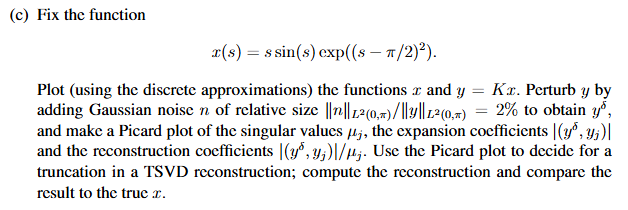

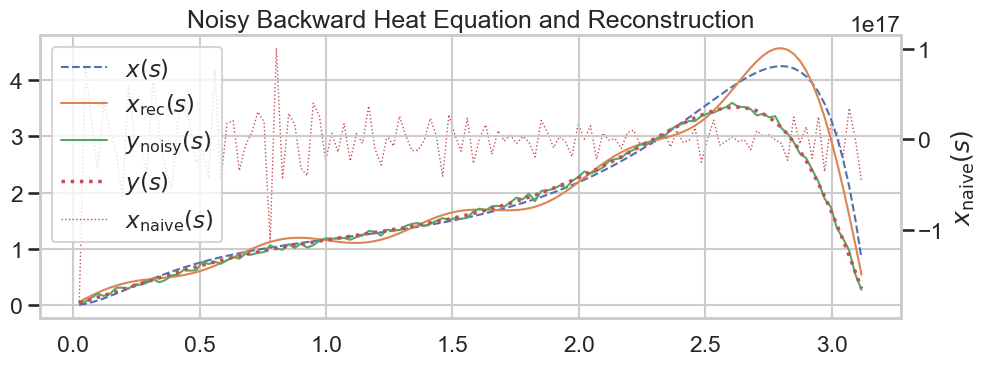

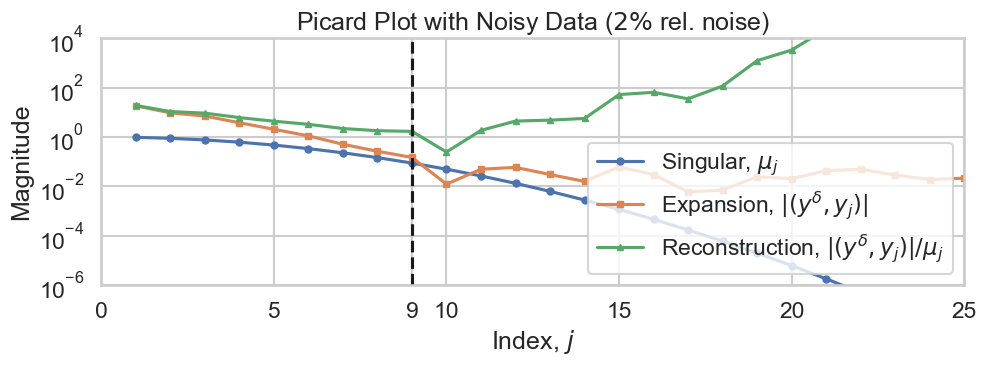

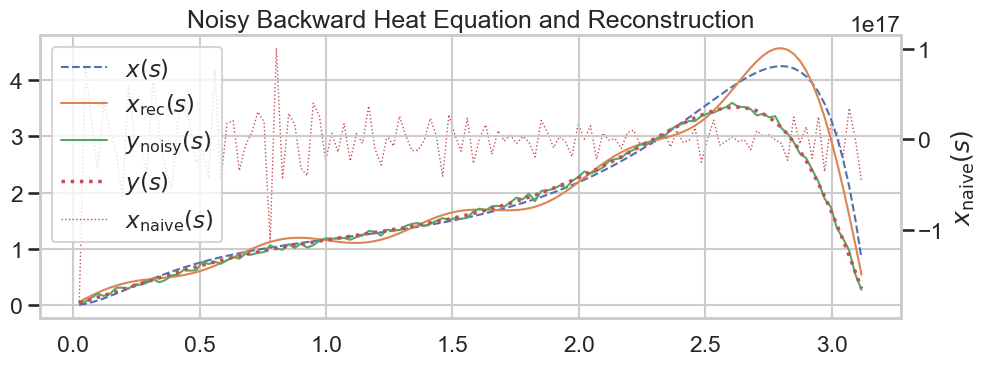

In [24]:
np.random.seed(42)


def x_func(s):
    return s * np.sin(s) * np.exp((s - np.pi / 2) ** 2)


x = x_func(s)
y = A @ x
unscaled_noise = np.random.randn(*y.shape)
unscaled_noise_level = np.linalg.norm(unscaled_noise)
noise_coeff = 0.02 * np.linalg.norm(y) / unscaled_noise_level
noise = noise_coeff * unscaled_noise
y_noisy = y + noise
x_naive = np.linalg.inv(A) @ y_noisy

# Prepare for Picard plot
singular_values = np.diagonal(S)
expansion_coefficients = np.abs(U.T @ y_noisy)
reconstruction_coefficients = expansion_coefficients / singular_values
plt.figure(figsize=(PAPER_WIDTH_IN, 4.0))
plt.plot(j, singular_values, marker="o", ls="-", ms=5, label="Singular, $μ_j$")
plt.plot(
    j,
    expansion_coefficients,
    marker="s",
    ls="-",
    ms=5,
    label="Expansion, $|(y^δ, y_j)|$",
)
plt.plot(
    j,
    reconstruction_coefficients,
    marker="^",
    ls="-",
    ms=5,
    label="Reconstruction, $|(y^δ, y_j)|/μ_j$",
)
plt.semilogy()
plt.legend(loc="lower right")
plt.xlim(0, 25)
plt.ylim(1e-6, 1e4)
plt.axvline(9, color="k", ls="--")
plt.xticks(list(plt.xticks()[0]) + [9])
plt.title("Picard Plot with Noisy Data ($2\\%$ rel. noise)")
plt.xlabel("Index, $j$")
plt.ylabel("Magnitude")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "1_c_picard_plot.png", dpi=600, bbox_inches="tight")

# Compute reconstruction
j_cutoff = 9  # Inclusive
S_truncated = S[:j_cutoff, :j_cutoff]
U_truncated = U[:, :j_cutoff]
V_truncated = V.T[:, :j_cutoff]
K_inv_truncated = V_truncated @ np.linalg.inv(S_truncated) @ U_truncated.T
x_reconstructed = K_inv_truncated @ y_noisy

plt.figure(figsize=(PAPER_WIDTH_IN, 4.0))
plt.plot(s, x_func(s), label="$x(s)$", ls="--", lw=1.5)
plt.plot(s, x_reconstructed, label="$x_\\text{rec}(s)$", lw=1.5)
plt.plot(s, y_noisy, label="$y_\\text{noisy}(s)$", lw=1.5)
plt.plot(s, y, label="$y(s)$", ls=":", lw=2.5)
plt.legend()

# Create new axis for naive solution
ax_main = plt.gca()
ax_noisy = plt.twinx()
ax_noisy.plot(s, x_naive, label="$x_\\text{naive}(s)$", color="C3", ls=":", lw=1)
ax_noisy.grid(False)
ax_main.set_zorder(1)
ax_main.patch.set_visible(False)
ax_noisy.set_ylabel("$x_\\text{naive}(s)$")

# Merge legends
handles1, labels1 = ax_main.get_legend_handles_labels()
handles2, labels2 = ax_noisy.get_legend_handles_labels()
ax_main.legend(handles1 + handles2, labels1 + labels2, loc="upper left")

plt.xlabel("Spatial Coordinate, $s$")
plt.title("Noisy Backward Heat Equation and Reconstruction")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "1_c_reconstruction.png", dpi=600, bbox_inches="tight")
display(plt.gcf())


# Task 2
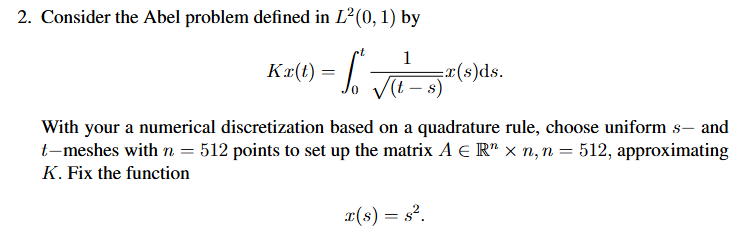
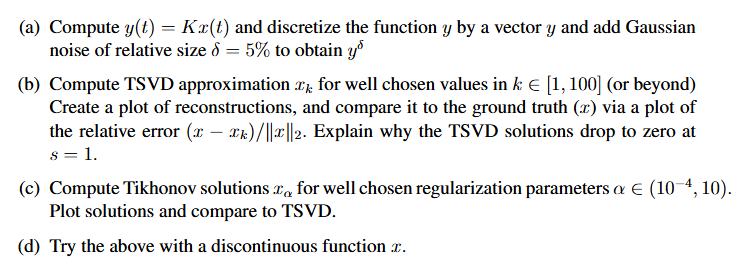

## Task 2.a
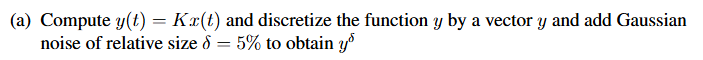

0.0625


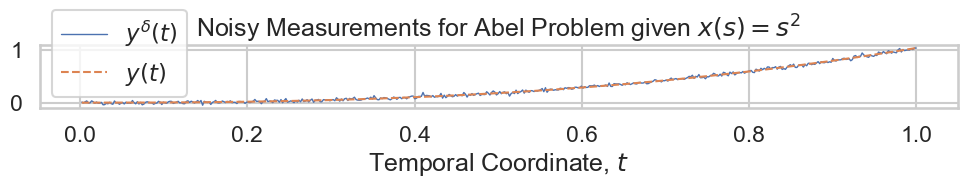

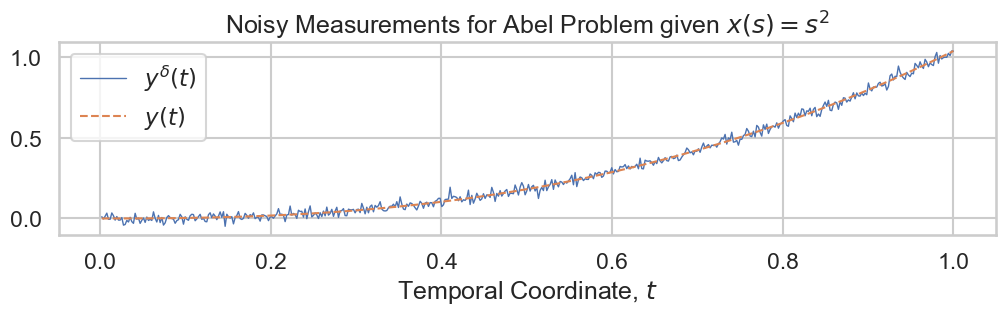

In [25]:
np.random.seed(42)

n = 512
a = 0
b = 1
h = (b - a) / n
print(np.sqrt(2 / h) * h)
s = a + (np.arange(n) + 0.5) * h
t = s + h / 2  # Shift t values to prevent singularity at t=s

s_mesh, t_mesh = np.meshgrid(s, t)

# Create A matrix
A = np.zeros((n, n))
indices = s_mesh < t_mesh  # Select according to integral
A[indices] = h / np.sqrt((t_mesh[indices] - s_mesh[indices]))


def x_1_func(s):
    return s**2


x_true = x_1_func(s)
y_true = A @ x_true

# Add noise
unscaled_noise = np.random.randn(*y_true.shape)
unscaled_noise_level = np.linalg.norm(unscaled_noise)
noise_coeff = 0.05 * np.linalg.norm(y_true) / unscaled_noise_level
noise = noise_coeff * unscaled_noise
y_noisy = y_true + noise

# Plot noisy measurements
plt.figure(figsize=(PAPER_WIDTH_IN, 2.2))
plt.plot(t, y_noisy, label="$y^δ(t)$", lw=1)
plt.plot(t, y_true, label="$y(t)$", lw=1.5, ls="--")
plt.title("Noisy Measurements for Abel Problem given $x(s) = s^2$")
plt.xlabel("Temporal Coordinate, $t$")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "2_a.png", dpi=600, bbox_inches="tight")
display(plt.gcf())

plt.gcf().set_size_inches(PAPER_WIDTH_IN, 3.5)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "2_a_large.png", dpi=600, bbox_inches="tight")

# Task 2.b
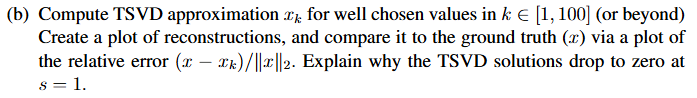

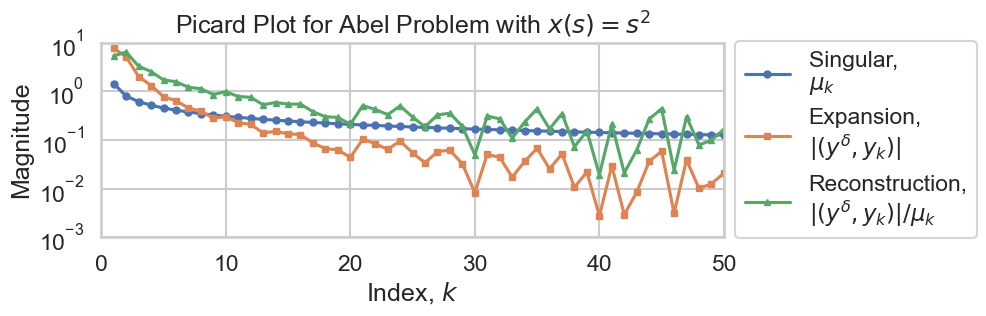

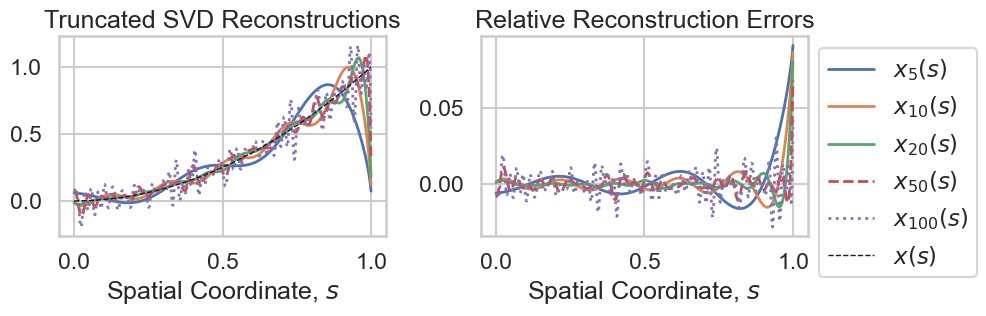

In [26]:
# Compute naive solution
x_naive = np.linalg.inv(A) @ y_noisy

# Perform SVD
j = np.arange(1, n + 1)
U, S, Vh = np.linalg.svd(A)

# Prepare Picard
expansion_coefficients = np.abs(U.T @ y_noisy)
reconstruction_coefficients = expansion_coefficients / S
# Perform Picard plot
plt.figure(figsize=(PAPER_WIDTH_IN, 3.5))
plt.title("Picard Plot for Abel Problem with $x(s) = s^2$")
plt.plot(j, S, marker="o", ls="-", ms=5, label="Singular,\n$μ_k$")
plt.plot(
    j,
    expansion_coefficients,
    marker="s",
    ls="-",
    ms=5,
    label="Expansion,\n$|(y^δ, y_k)|$",
)
plt.plot(
    j,
    reconstruction_coefficients,
    marker="^",
    ls="-",
    ms=5,
    label="Reconstruction,\n$|(y^δ, y_k)|/μ_k$",
)
plt.xlim(0, 50)
plt.ylim(1e-3, 1e1)
plt.xlabel("Index, $k$")
plt.ylabel("Magnitude")
plt.semilogy()
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "2_b_picard.png", dpi=600, bbox_inches="tight")

# Reconstruction plots
fig, (ax_real, ax_error) = plt.subplots(
    1, 2, figsize=(PAPER_WIDTH_IN, 3.5), sharex=True
)

# ks = [5, 10, 25, 50, 100, "naive"]
ks = [5, 10, 20, 50, 100]
plot_kws_config = {
    50: {"ls": "--"},
    100: {"ls": ":"},
}
for k in ks:
    if k == "naive":
        x_reconstructed = x_naive
        show_error = False
    else:
        # To TSVD
        U_truncated = U[:, :k]
        S_truncated = np.diag(S)[:k, :k]
        V_truncated = Vh.T[:, :k]
        A_inv_truncated = V_truncated @ np.linalg.inv(S_truncated) @ U_truncated.T
        x_reconstructed = A_inv_truncated @ y_noisy
        show_error = True

    plot_kws = plot_kws_config.get(k, {})
    plot_kws.setdefault("lw", 2)
    plot_kws.setdefault("ls", "-")
    real_plot = ax_real.plot(s, x_reconstructed, label=f"$x_{{{k}}}(s)$", **plot_kws)

    if show_error:
        residual = x_true - x_reconstructed
        relative_error = (x_true - x_reconstructed) / np.linalg.norm(x_true)
        ax_error.plot(s, relative_error, color=real_plot[0].get_color(), **plot_kws)

ax_real.plot(s, x_true, label="$x(s)$", lw=1, ls="--", color="k")
ax_real.set_xlabel("Spatial Coordinate, $s$")
ax_error.set_xlabel("Spatial Coordinate, $s$")
ax_real.set_title("Truncated SVD Reconstructions")
ax_error.set_title("Relative Reconstruction Errors")

# Legend stuff
# Collect all handles and labels from both axes
handles_real, labels_real = ax_real.get_legend_handles_labels()
handles_error, labels_error = ax_error.get_legend_handles_labels()

# Place combined legend on ax_error, to the right
ax_error.legend(
    handles_real + handles_error,
    labels_real + labels_error,
    loc="upper left",
    bbox_to_anchor=(1, 1),
)

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "2_b_reconstructions.png", dpi=600, bbox_inches="tight")


# 2.c - Tikhonov
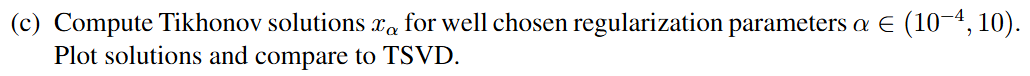

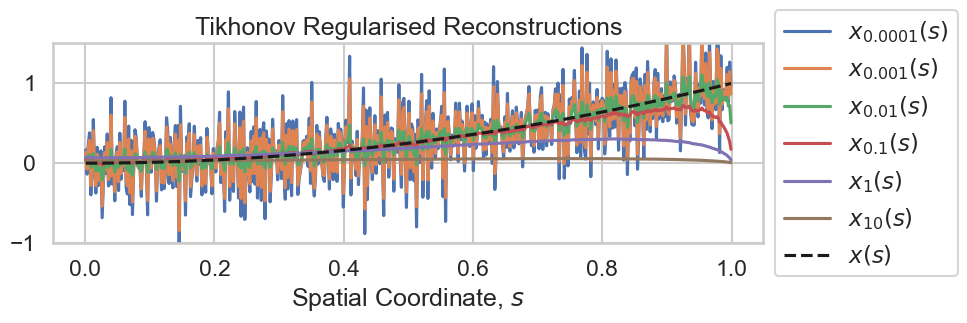

In [27]:
alphas = np.geomspace(1e-4, 10, 10)
alphas = [1e-4, 1e-3, 1e-2, 1e-1, 1, 10]

plt.figure(figsize=(PAPER_WIDTH_IN, 3.5))
for alpha in alphas:
    x_tikhonov = np.linalg.inv(A.T @ A + alpha * np.eye(n)) @ A.T @ y_noisy
    plt.plot(s, x_tikhonov, label=f"$x_{{{alpha}}}(s)$")

# plt.plot(s, x_naive, label='$x_{\\mathrm{naive}}(s)$', ls=":")
plt.plot(s, x_true, label="$x(s)$", ls="--", color="k")
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.title("Tikhonov Regularised Reconstructions")
plt.xlabel("Spatial Coordinate, $s$")
plt.ylim(-1, 1.5)
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "2_c_tikhonov_reconstructions.png", dpi=600, bbox_inches="tight"
)


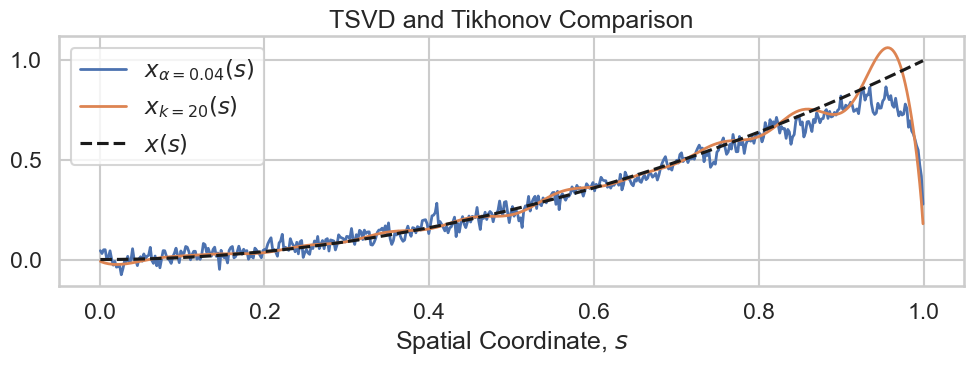

In [28]:
# Best TSVD
k = 20
U, S, Vh = np.linalg.svd(A)
U_truncated = U[:, :k]
S_truncated = np.diag(S)[:k, :k]
V_truncated = Vh.T[:, :k]
A_inv_truncated = V_truncated @ np.linalg.inv(S_truncated) @ U_truncated.T
x_best_tsvd = A_inv_truncated @ y_noisy

# Best Tikhonov
alpha = 4e-2
x_best_tikhonov = np.linalg.inv(A.T @ A + alpha * np.eye(n)) @ A.T @ y_noisy

plt.figure(figsize=(PAPER_WIDTH_IN, 4.0))
plt.plot(s, x_best_tikhonov, label=f"$x_{{α={alpha}}}(s)$", lw=2)
plt.plot(s, x_best_tsvd, label=f"$x_{{k={k}}}(s)$", lw=2)
plt.plot(s, x_true, label="$x(s)$", ls="--", color="k")
plt.legend()
plt.title("TSVD and Tikhonov Comparison")
plt.xlabel("Spatial Coordinate, $s$")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "2_c_tsvd_vs_tikhonov.png", dpi=600, bbox_inches="tight")

# 2.d - Discontinuous Function
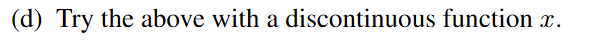

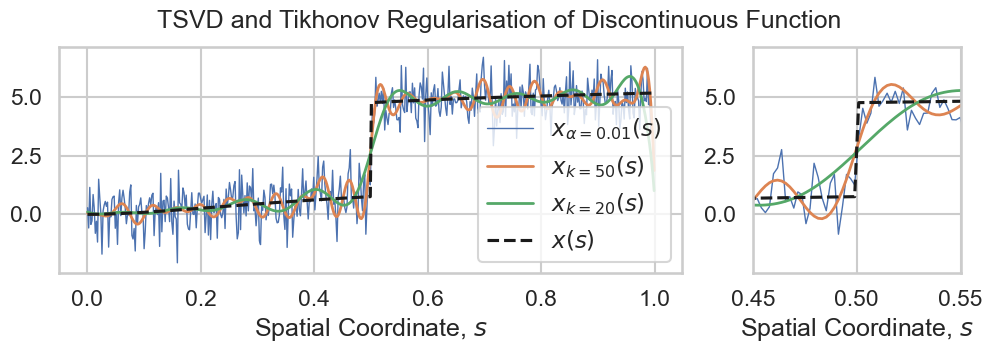

In [29]:
def heaviside_step(x):
    return 0.5 * (np.sign(x) + 1)


def x_func_discontinuous(s):
    return x_func(s) + 4 * heaviside_step(s - 1 / 2)


x_true = x_func_discontinuous(s)
y_true = A @ x_true

# Add noise
np.random.seed(1234)
unscaled_noise = np.random.randn(*y_true.shape)
unscaled_noise_level = np.linalg.norm(unscaled_noise)
noise_coeff = 0.05 * np.linalg.norm(y_true) / unscaled_noise_level
noise = noise_coeff * unscaled_noise
y_noisy = y_true + noise

# Best TSVD
k_best = 50
U, S, Vh = np.linalg.svd(A)
U_truncated = U[:, :k_best]
S_truncated = np.diag(S)[:k_best, :k_best]
V_truncated = Vh.T[:, :k_best]
A_inv_truncated = V_truncated @ np.linalg.inv(S_truncated) @ U_truncated.T
x_best_tsvd = A_inv_truncated @ y_noisy

# Slow TSVD
k_slow = 20
U, S, Vh = np.linalg.svd(A)
U_truncated = U[:, :k_slow]
S_truncated = np.diag(S)[:k_slow, :k_slow]
V_truncated = Vh.T[:, :k_slow]
A_inv_truncated = V_truncated @ np.linalg.inv(S_truncated) @ U_truncated.T
x_slow_tsvd = A_inv_truncated @ y_noisy

# Best Tikhonov
alpha = 1e-2
x_best_tikhonov = np.linalg.inv(A.T @ A + alpha * np.eye(n)) @ A.T @ y_noisy

fig, (ax_main, ax_zoom) = plt.subplots(
    1, 2, figsize=(PAPER_WIDTH_IN, 4.0), gridspec_kw={"width_ratios": [3, 1]}
)
ax_main.plot(s, x_best_tikhonov, label=f"$x_{{α={alpha}}}(s)$", lw=1)
ax_zoom.plot(s, x_best_tikhonov, label=f"$x_{{α={alpha}}}(s)$", lw=1)
ax_main.plot(s, x_best_tsvd, label=f"$x_{{k={k_best}}}(s)$", lw=2)
ax_zoom.plot(s, x_best_tsvd, label=f"$x_{{k={k_best}}}(s)$", lw=2)
ax_main.plot(s, x_slow_tsvd, label=f"$x_{{k={k_slow}}}(s)$", lw=2)
ax_zoom.plot(s, x_slow_tsvd, label=f"$x_{{k={k_slow}}}(s)$", lw=2)
ax_main.plot(s, x_true, label="$x(s)$", ls="--", color="k")
ax_zoom.plot(s, x_true, label="$x(s)$", ls="--", color="k")
ax_main.legend()
fig.suptitle(
    "TSVD and Tikhonov Regularisation of Discontinuous Function", y=0.90, fontsize=TITLE_SIZE_PT
)
ax_main.set_xlabel("Spatial Coordinate, $s$")
ax_zoom.set_xlabel("Spatial Coordinate, $s$")
ax_zoom.set_xlim(0.45, 0.55)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "2_d_discontinuous.png", dpi=600, bbox_inches="tight")


# Task 3
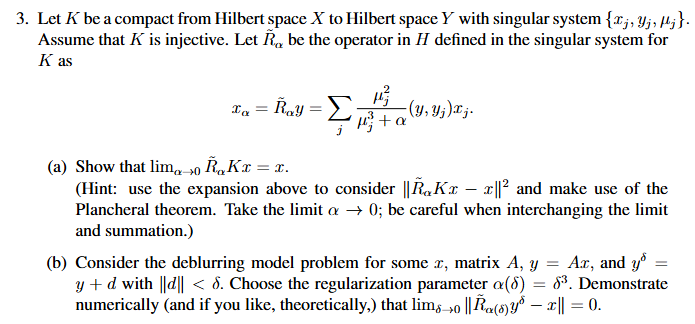

## Task 3.b - Deblurring Problem
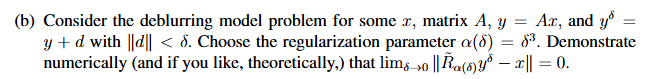

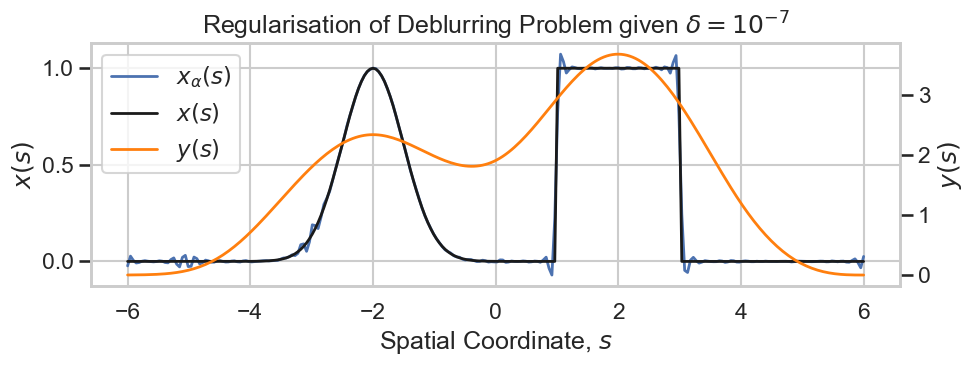

In [30]:
# Deblurring problem
n = 2**8
h = 12 / n
n4 = n // 4
delta = 1e-7

alpha = delta**2

r1 = np.zeros(n)

# Cosine values for the formula
c = np.cos(np.arange(-1, n4 + 1) * 4 * np.pi / n)

# Fill in the first n/4 entries
r1[:n4] = h + 9 / (h * np.pi**2) * (2 * c[1 : n4 + 1] - c[:n4] - c[2 : n4 + 2])

# Middle entry
r1[n4] = h / 2 + 9 / (h * np.pi**2) * (np.cos(4 * np.pi / n) - 1)

A = toeplitz(r1)


# Set up true image
def tophat_func(s, width, center):
    return heaviside_step(s - (center - width / 2)) - heaviside_step(
        s - (center + width / 2)
    )


def x_deblur_func(s):
    return np.exp(-((s + 2) ** 2) / 0.5) + tophat_func(s, 2, 2)


s = np.linspace(-6, 6, n)

x_true = x_deblur_func(s)
y_true = A @ x_true

# Add noise
np.random.seed(42)
unscaled_noise = np.random.randn(*y_true.shape)
unscaled_noise_level = np.linalg.norm(unscaled_noise)
noise_coeff = delta * np.linalg.norm(y_true) / unscaled_noise_level
noise = noise_coeff * unscaled_noise
y_noisy = y_true + noise

# Compute regularisation
U, S, Vh = np.linalg.svd(A)

Y_basis = U
X_basis = Vh.T
mu = S
y_yj_ip = Y_basis.T @ y_noisy
filter_factors = mu**2 / (mu**3 + alpha)
coefficients = filter_factors * y_yj_ip
x_deblurred = X_basis @ coefficients

# Naive solution
x_true_naive = np.linalg.inv(A) @ y_true
x_naive = np.linalg.inv(A) @ y_noisy

fig, ax_x = plt.subplots(figsize=(PAPER_WIDTH_IN, 4.0))
ax_y = ax_x.twinx()
# ax_x.plot(s, x_true_naive, label='$x_{\\mathrm{naive}}(s)$', lw=1)
# ax_x.plot(s, x_naive, label='$x_{\\mathrm{naive}}^δ(s)$', lw=1)
ax_x.plot(s, x_deblurred, label="$x_α(s)$", lw=2)
ax_x.plot(s, x_true, label="$x(s)$", lw=2, c="k")
ax_y.plot(s, y_true, label="$y(s)$", lw=2, c="tab:orange")

ax_y.grid(False)

# Legend
handles_x, labels_x = ax_x.get_legend_handles_labels()
handles_y, labels_y = ax_y.get_legend_handles_labels()
ax_x.legend(handles_x + handles_y, labels_x + labels_y, loc="upper left")
ax_x.set_xlabel("Spatial Coordinate, $s$")
ax_x.set_ylabel("$x(s)$")
ax_y.set_ylabel("$y(s)$")

ax_x.set_title(
    f"Regularisation of Deblurring Problem given $δ={sci_notation(delta, 0)}$"
)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "3_b_validation.png", dpi=600, bbox_inches="tight")

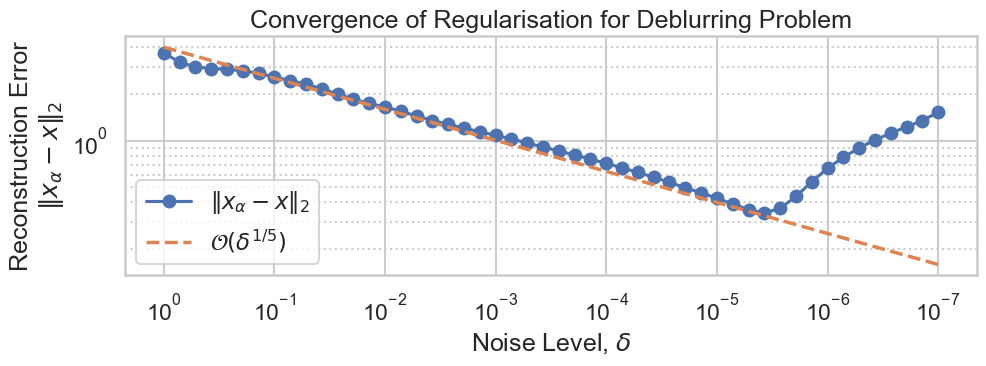

In [31]:
# Investigate convergence
deltas = np.geomspace(1.0, 1e-7, 50)

machine_prec = np.finfo(float).eps
machine_prec_transformed = np.cbrt(machine_prec)

convergence_data = []
for delta in deltas:
    alpha = delta**3

    # Compute regularisation
    y_yj_ip = Y_basis.T @ y_noisy
    filter_factors = mu**2 / (mu**3 + alpha)
    coefficients = filter_factors * y_yj_ip
    x_deblurred = X_basis @ coefficients

    error_norm = np.linalg.norm(x_deblurred - x_true, ord=2)
    convergence_data.append({"delta": delta, "alpha": alpha, "error_norm": error_norm})


df = pd.DataFrame(convergence_data)

fig, ax = plt.subplots(figsize=(PAPER_WIDTH_IN, 4.0))
ax.xaxis.set_inverted(True)
plt.plot(df["delta"], df["error_norm"], marker="o", ls="-", label="$\\|x_α - x\\|_2$")
plt.plot(
    df["delta"],
    4 * df["delta"] ** (1 / 5),
    ls="--",
    lw=2.5,
    label="$\\mathcal{O}(δ^{1/5})$",
)
# plt.axvline(
#     machine_prec_transformed, color="k", ls="--", lw=1.5, label="$\\sqrt[3]{ε}$"
# )
plt.loglog()
plt.grid(axis="y", which="minor", ls=":")
plt.legend()
plt.title("Convergence of Regularisation for Deblurring Problem")
plt.xlabel("Noise Level, $δ$")
plt.ylabel("Reconstruction Error\n$\\|x_α - x\\|_2$")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "3_b_convergence.png", dpi=600, bbox_inches="tight")


In [32]:
print("Float precision:", machine_prec)
print("Float precision transformed:", machine_prec_transformed)

Float precision: 2.220446049250313e-16
Float precision transformed: 6.055454452393339e-06
